## RS Oph Spectral Index Plot

In [1]:
#imports imports imports
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models
from scipy.stats import chisquare as CHI

In [2]:
#All of the data

#NEED to go and grab the data that Laura wants in as well

In [304]:
data = (

[59439.04,	2.6,	4.71,	0.14],
[59439.04,	3.4,	5.328,	0.093],
[59439.04,	5.1,	10.012,	0.058],
[59439.04,	7,	15.607,	0.057],
[59439.04,	13.7,	24.088,	0.055],
[59439.04,	16.5,	25.573,	0.059],
[59439.04,	31.1,	35.973,	0.14],
[59439.04,	34.9,	38.318,	0.16],
    
[59440.08,	2.6,	18.206,	0.11],
[59440.08,	3.4,	23.366,	0.1],
[59440.08,	5.1,	33.454,	0.059],
[59440.08,	7,	39.663,	0.055],
[59440.08,	13.7,	40.939,	0.062],
[59440.08,	16.5,	41.636,	0.063],
[59440.08,	31.1,	44.762,	0.14],
[59440.08,	34.9,	46.68,	0.15],
			
[59443.99,	2.6,	68.929,	0.37],
[59443.99,	3.4,	73.933,	0.11],
[59443.99,	5.1,	67.597,	0.087],
[59443.99,	7,	58.65,	0.068],
[59443.99,	13.7,	47.847,	0.066],
[59443.99,	16.5,	46.81,	0.063],
[59443.99,	31.1,	48.13,	0.14],
[59443.99,	34.9,	49.924,	0.16],
			
[59446.01,	2.6,	88.695,	0.21],
[59446.01,	3.4,	78.259,	0.11],
[59446.01,	5.1,	60.457,	0.065],
[59446.01,	7,	50.875,	0.057],
[59446.01,	13.7,	43.692,	0.054],
[59446.01,	16.5,	42.418,	0.055],
[59446.01,	31.1,	46.076,	0.12],
[59446.01,	34.9,	48.49,	0.14],
			
[59446.99,	2.6,	84.443,	0.34],
[59446.99,	3.4,	82.034,	0.13],
[59446.99,	5.1,	63.977,	0.083],
[59446.99,	7,	51.883,	0.062],
[59446.99,	13.7,	41.854,	0.056],
[59446.99,	16.5,	40.83,	0.056],
[59446.99,	31.1,	43.653,	0.12],
[59446.99,	34.9,	45.965,	0.13],
			
[59451.01,	2.6,	92.534,	0.24],
[59451.01,	3.4,	83.135,	0.19],
[59451.01,	5.1,	61.832,	0.074],
[59451.01,	7,	52.291,	0.059],
[59451.01,	13.7,	44.133,	0.054],
[59451.01,	16.5,	42.894,	0.061],
[59451.01,	31.1,	47.067,	0.12],
[59451.01,	34.9,	48.103,	0.13],
			
[59461.01,	2.6,	94.467,	0.22],
[59461.01,	3.4,	85.812,	0.17],
[59461.01,	5.1,	65.115,	0.074],
[59461.01,	7,	57.617,	0.064],
[59461.01,	13.7,	54.102,	0.06],
[59461.01,	16.5,	54.536,	0.065],
[59461.01,	31.1,	70.776,	0.15],
[59461.01,	34.9,	77.042,	0.16],
			
[59463.02,	2.6,	88.638,	0.2],
[59463.02,	3.4,	80.579,	0.17],
[59463.02,	5.1,	60.766,	0.069],
[59463.02,	7,	56.003,	0.062],
[59463.02,	13.7,	51.457,	0.068],
[59463.02,	16.5,	54.259,	0.074],
[59463.02,	31.1,	75.224,	0.17],
[59463.02,	34.9,	82.831,	0.18],
			
[59466.04,	2.6,	58.862,	0.17],
[59466.04,	3.4,	58.434,	0.13],
[59466.04,	5.1,	54.499,	0.067],
[59466.04,	7,	54.364,	0.068],
			
[59467.99,	2.6,	81.96,	0.23],
[59467.99,	3.4,	75.044,	0.15],
[59467.99,	5.1,	60.253,	0.061],
[59467.99,	7,	55.839,	0.055],
[59467.99,	13.7,	55.46,	0.057],
[59467.99,	16.5,	57.657,	0.059],
[59467.99,	31.1,	85.302,	0.13],
[59467.99,	34.9,	94.908,	0.14],
			
[59470.01,	2.6,	74.216,	0.24],
[59470.01,	3.4,	67.992,	0.14],
[59470.01,	5.1,	56.608,	0.058],
[59470.01,	7,	54.465,	0.056],
[59470.01,	13.7,	56.891,	0.061],
[59470.01,	16.5,	60.279,	0.063],
[59470.01,	31.1,	92.384,	0.14],
[59470.01,	34.9,	103.52,	0.15],
			
[59487.96,	2.6,	65.358,	0.18],
[59487.96,	3.4,	60.804,	0.13],
[59487.96,	5.1,	49.879,	0.061],
[59487.96,	7,	46.096,	0.058],
[59487.96,	13.7,	51.336,	0.074],
[59487.96,	16.5,	55.64,	0.083],
[59487.96,	31.1,	92.061,	0.14],
[59487.96,	34.9,	103.31,	0.16],
			
[59510.94,	2.6,	27.414,	0.13],
[59510.94,	3.4,	30.985,	0.086],
[59510.94,	5.1,	36.454,	0.052],
[59510.94,	7,	38.595,	0.05],		
			
[59511.92,	2.6,	36.139,	0.13],
[59511.92,	3.4,	36.456,	0.11],
[59511.92,	5.1,	36.228,	0.053],
[59511.92,	7,	38.215,	0.053],
[59511.92,	13.7,	45.791,	0.053],
[59511.92,	16.5,	50.332,	0.052],
[59511.92,	31.1,	79.492,	0.12],
[59511.92,	34.9,	88.439,	0.13],
			
[59523.82,	2.6,	32.964,	0.13],
[59523.82,	3.4,	32.519,	0.092],
[59523.82,	5.1,	31.849,	0.053],
[59523.82,	7,	32.08,	0.049],
[59523.82,	13.7,	38.122,	0.049],
[59523.82,	16.5,	41.511,	0.05],
[59523.82,	31.1,	66.05,	0.11],
[59523.82,	34.9,	72.993,	0.12],
			
[59574.76,	2.6,	17.902,	0.2],
[59574.76,	3.4,	17.739,	0.18],
[59574.76,	5.1,	17.481,	0.064],
[59574.76,	7,	19.527,	0.06],
[59574.76,	13.7,	25.248,	0.067],
[59574.76,	16.5,	26.955,	0.061],
[59574.76,	31.1,	42.236,	0.34],
[59574.76,	34.9,	47.137,	0.35],
			
[59588.66,	2.6,	24.59,	0.16],
[59588.66,	3.4,	22.702,	0.14],
[59588.66,	5.1,	18.554,	0.06],
[59588.66,	7,	18.619,	0.051],
[59588.66,	13.7,	21.6,	0.051],
[59588.66,	16.5,	22.164,	0.053],
[59588.66,	31.1,	26.488,	0.1],
[59588.66,	34.9,	27.475,	0.11],
			
[59590.61,	2.6,	24.388,	0.21],
[59590.61,	3.4,	22.617,	0.11],
[59590.61,	5.1,	19.794,	0.062],
[59590.61,	7,	19.169,	0.052],
[59590.61,	13.7,	21.908,	0.051],
[59590.61,	16.5,	22.994,	0.047],
[59590.61,	31.1,	28.341,	0.11],
[59590.61,	34.9,	29.746,	0.12],
			
[59595.61,	2.6,	23.163,	0.16],
[59595.61,	3.4,	20.742,	0.13],
[59595.61,	5.1,	17.488,	0.056],
[59595.61,	7,	17.871,	0.057],
[59595.61,	13.7,	20.702,	0.05],
[59595.61,	16.5,	21.855,	0.048],
[59595.61,	31.1,	27.116,	0.11],
[59595.61,	34.9,	28.356,	0.11],
			
[60034.47,	2.6,	3.295,	0.17],
[60034.47,	3.4,	3.342,	0.12],
[60034.47,	5.1,	2.765,	0.052],
[60034.47,	7,	2.347,	0.049],
[60034.47,	13.7,	1.672,	0.05],
[60034.47,	16.5,	1.526,	0.051],
[60034.47,	31.1,	0.87,	0.1],
[60034.47,	34.9,	0.862,	0.11],
			
[60049.34,	2.6,	2.777,	0.17],
[60049.34,	3.4,	2.82,	0.078],
[60049.34,	5.1,	2.684,	0.053],
[60049.34,	7,	2.373,	0.046],
[60049.34,	13.7,	1.67,	0.048],
[60049.34,	16.5,	1.541,	0.048],
[60049.34,	31.1,	1.077,	0.11],
[60049.34,	34.9,	1.113,	0.12],
			
[60131.12,	2.6,	1.808,	0.017],
[60131.12,	3.4,	1.999,	0.014],
[60131.12,	5.1,	2.163,	0.016],
[60131.12,	7,	2.336,	0.018],
[60131.12,	13.7,	1.933,	0.02],
[60131.12,	16.5,	1.923,	0.022],
[60131.12,	31.1,	1.336,	0.066],
[60131.12,	34.9,	1.306,	0.079],
)

df =  pd.DataFrame(data, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

In [305]:

#For the data from uGMRT, they already had the error, data in band-2 (125−250 MHz), band-3
#(250−500 MHz), band-4 (550−850 MHz), and band-5 (1000−1460 MHz)
#and In addition to the errors on flux densities from task JMFIT, we add (in quadrature) a 10% error in bands-3, 4, and 5 and a 15% error in band-2 to account for the calibration uncertainties
#I went in and reversed this (for bands 3, 4 and 5 i multipled the error by 0.9, and for the band 2 I multiplied the error by 0.85)
#Using original_err = np.sqrt( err_stated**2 - (flux*0.1)**2 )
#The data from MeerKAT and LOFAR both had a error of 10% addded (Ruiter et al. 2023), using the same eq as above

#day 3
E0 = ([ 59437.7, 1284*0.001, 0.28, np.sqrt( 0.045**2 - (0.28*0.1)**2 ) ], #MeerKAT
      [59437.8, 816*0.001, 0.49, np.sqrt( 0.068**2 - (0.49*0.1)**2 )],) #MeerKAT
#day 5
E1 = ([ 59439.6, 1284*0.001, 1.7, np.sqrt( 0.18**2 - (1.7*0.1)**2 )], #MeerKAT
    [59439.04,	2.6,	4.71,	0.14],
[59439.04,	3.4,	5.328,	0.093],
[59439.04,	5.1,	10.012,	0.058],
[59439.04,	7,	15.607,	0.057],
[59439.04,	13.7,	24.088,	0.055],
[59439.04,	16.5,	25.573,	0.059],
[59439.04,	31.1,	35.973,	0.14],
[59439.04,	34.9,	38.318,	0.16],)

#day 6
E2 = ( [59440.6, 816*0.001, 1.4, np.sqrt( 0.16**2 - (1.4*0.1)**2 )], #MeerKAT
      [59440.6, 1284*0.001, 8.6, np.sqrt( 0.87**2 - (8.6*0.1)**2 ) ], #MeerKAT
    
[59440.08,	2.6,	18.206,	0.11],
[59440.08,	3.4,	23.366,	0.1],
[59440.08,	5.1,	33.454,	0.059],
[59440.08,	7,	39.663,	0.055],
[59440.08,	13.7,	40.939,	0.062],
[59440.08,	16.5,	41.636,	0.063],
[59440.08,	31.1,	44.762,	0.14],
[59440.08,	34.9,	46.68,	0.15],)

#day 10
E3 = ( [59444.8,816*0.001, 54.5, np.sqrt( 5.5**2 - (54.5*0.1)**2 )], #MeerKAT
      [59444.9, 1284*0.001, 70.5, np.sqrt( 7.1**2 - (70.5*0.1)**2 )], #MeerKAT
    
    [59443.99,	2.6,	68.929,	0.37],
[59443.99,	3.4,	73.933,	0.11],
[59443.99,	5.1,	67.597,	0.087],
[59443.99,	7,	58.65,	0.068],
[59443.99,	13.7,	47.847,	0.066],
[59443.99,	16.5,	46.81,	0.063],
[59443.99,	31.1,	48.13,	0.14],
[59443.99,	34.9,	49.924,	0.16],
)
#day 12
E4 = ([59446.01,	2.6,	88.695,	0.21],
[59446.01,	3.4,	78.259,	0.11],
[59446.01,	5.1,	60.457,	0.065],
[59446.01,	7,	50.875,	0.057],
[59446.01,	13.7,	43.692,	0.054],
[59446.01,	16.5,	42.418,	0.055],
[59446.01,	31.1,	46.076,	0.12],
[59446.01,	34.9,	48.49,	0.14],)

#day13
E5 = ([59446.99,	2.6,	84.443,	0.34],
[59446.99,	3.4,	82.034,	0.13],
[59446.99,	5.1,	63.977,	0.083],
[59446.99,	7,	51.883,	0.062],
[59446.99,	13.7,	41.854,	0.056],
[59446.99,	16.5,	40.83,	0.056],
[59446.99,	31.1,	43.653,	0.12],
[59446.99,	34.9,	45.965,	0.13],)

#day17
E6 = (			
[59451.01,	2.6,	92.534,	0.24],
[59451.01,	3.4,	83.135,	0.19],
[59451.01,	5.1,	61.832,	0.074],
[59451.01,	7,	52.291,	0.059],
[59451.01,	13.7,	44.133,	0.054],
[59451.01,	16.5,	42.894,	0.061],
[59451.01,	31.1,	47.067,	0.12],
[59451.01,	34.9,	48.103,	0.13],
			)
#day24
E6_5 = ([59458.6, 1284*0.001, 76.1, np.sqrt( np.abs(7.6**2 - (76.1*0.1)**2) )], #MeerKAT 
       [59458.6, 816*0.001, 78.7, np.sqrt( 7.9**2 - (78.7*0.1)**2 )], #MeerKAT
       [59458.7, 154*0.001, 39.9, np.sqrt( 5.7**2 - (39.9*0.1)**2 )],  #LOFAR
        [59459.53, 1.36, 85.1,  np.sqrt( 8.6**2 - (85.1*0.1)**2 ) ], #uGMRT, UT: 2021 Sep 02.53
        [59457.17, 0.69, 77.5,    np.sqrt( 8**2 - (77.5*0.1)**2 )] #uGMRT 2021 Aug 31.67 23.17 0.69 77.50 ± 8.00
       )


#day27
E7 = ([59461.01,	2.6,	94.467,	0.22],
[59461.01,	3.4,	85.812,	0.17],
[59461.01,	5.1,	65.115,	0.074],
[59461.01,	7,	57.617,	0.064],
[59461.01,	13.7,	54.102,	0.06],
[59461.01,	16.5,	54.536,	0.065],
[59461.01,	31.1,	70.776,	0.15],
[59461.01,	34.9,	77.042,	0.16],)

#day29
E8 = (
    [59462.51, .4, 73.1, np.sqrt( 11.2**2 - (73.1*0.1)**2 )], #uGMRT, 2021 Sep 05.51 28.01 0.40 73.10 ± 11.20
    [59463.02,	2.6,	88.638,	0.2],
[59463.02,	3.4,	80.579,	0.17],
[59463.02,	5.1,	60.766,	0.069],
[59463.02,	7,	56.003,	0.062],
[59463.02,	13.7,	51.457,	0.068],
[59463.02,	16.5,	54.259,	0.074],
[59463.02,	31.1,	75.224,	0.17],
[59463.02,	34.9,	82.831,	0.18],)

#day32
E9 = ([59466.04,	2.6,	58.862,	0.17],
[59466.04,	3.4,	58.434,	0.13],
[59466.04,	5.1,	54.499,	0.067],
[59466.04,	7,	54.364,	0.068],)

#day34
E10 = ( [ 59468.6, 816*0.001, 73.5, np.sqrt( 7.4**2 - (73.5*0.1)**2 )], #MeerKAT
    [ 59468.7, 1284*0.001, 70.8, np.sqrt( 7.1**2 - (70.8*0.1)**2 )], #MeerKAT
    [ 59468.7, 154*0.001, 64.4, np.sqrt( 7.6**2 - (64.4*0.1)**2 )], #LOFAR
    [59467.99,	2.6,	81.96,	0.23],
[59467.99,	3.4,	75.044,	0.15],
[59467.99,	5.1,	60.253,	0.061],
[59467.99,	7,	55.839,	0.055],
[59467.99,	13.7,	55.46,	0.057],
[59467.99,	16.5,	57.657,	0.059],
[59467.99,	31.1,	85.302,	0.13],
[59467.99,	34.9,	94.908,	0.14],)

#day36
E11 = ([59470.01,	2.6,	74.216,	0.24],
[59470.01,	3.4,	67.992,	0.14],
[59470.01,	5.1,	56.608,	0.058],
[59470.01,	7,	54.465,	0.056],
[59470.01,	13.7,	56.891,	0.061],
[59470.01,	16.5,	60.279,	0.063],
[59470.01,	31.1,	92.384,	0.14],
[59470.01,	34.9,	103.52,	0.15],
      [59471.73, 1.37, 61,  np.sqrt( 6.3**2 - (61*0.1)**2 )], #uGMRT, UT = 2021 Sep 14.73
#maybe?
       [59473.7, 0.46, 71.7,  np.sqrt( 7.8**2 - (71.7*0.1)**2 )], #uGMRT 2021 Sep 16.70 39.20 0.46 71.70 ± 7.80
       [59474.67, 0.69, 78,  np.sqrt( 7.9**2 - (78*0.1)**2 )], # uGMRT, 2021 Sep 17.67 40.17 0.69 78.00 ± 7.90
      )

#not including 
#2021 Sep 26.69 49.19 1.36 43.10 ± 4.70

#day54
E12 = ([ 59483.6, 1284*0.001, 66.8, np.sqrt( 6.7**2 - (66.8*0.1)**2 )], #MeerKAT
    [ 59483.6, 816*0.001, 72, np.sqrt( 7.2**2 - (72*0.1)**2 )], #MeerKAT
    [ 59483.6, 54*0.001,61.4, np.sqrt( 29.7**2 - (61.4*0.1)**2 ) ], #LOFAR
     #  [ 59483.7, 154*0.001,49.8, np.sqrt( 7.4**2 - (49.8*0.1)**2 ) ], #LOFAR
    [59487.96,	2.6,	65.358,	0.18],
[59487.96,	3.4,	60.804,	0.13],
[59487.96,	5.1,	49.879,	0.061],
[59487.96,	7,	46.096,	0.058],
[59487.96,	13.7,	51.336,	0.074],
[59487.96,	16.5,	55.64,	0.083],
[59487.96,	31.1,	92.061,	0.14],
[59487.96,	34.9,	103.31,	0.16],
      [59488.58, 0.69, 72.1, np.sqrt( 7.7**2 - (72.1*0.1)**2 )], #2021 Oct 01.58 54.08 0.69 72.10 ± 7.70
       [59487.62, 0.45, 80, np.sqrt( 8.1**2 - (80*0.1)**2 )], #uGMRT, 2021 Sep 30.62 53.12 0.45 80.00 ± 8.10
       [59487.53, 0.147, 33.2, np.sqrt( 8.2**2 - (33.2*0.1)**2 )], #uGMRT, band 2, 2021 Sep 30.53 53.03 0.147 33.20 ± 8.20
     # [59488.67, 1.36, 45.9, np.sqrt( 4.6**2 - (45.9*0.1)**2 )], #uGMRT, UT:2021 Sep 31.67 54.17 1.36 45.90 ± 4.60
      )

#didn't use
#2021 Oct 05.34 57.84 1.36 60.40 ± 6.00
#2021 Oct 03.42 55.92 0.46 75.80 ± 11.50


#day 61-65
E12_5 = (
    [59495.38, 0.145, 48.9, np.sqrt( 10.8**2 - (48.9*0.15)**2 )], #uGMRT, 2021 Oct 08.38 60.88 0.146 48.90 ± 10.80
    [59495.41, 0.66, 58.9, np.sqrt( 6.1**2 - (58.9*0.1)**2 )], #uGMRT, 2021 Oct 08.41 60.91 0.66 58.90 ± 6.10
    [59498.6,  816*0.001,  59.2,  np.sqrt( np.abs( 5.9**2 - (59.2*0.1)**2) )], #MeerKAT
 [59498.7,  1284*0.001,   53.6,  np.sqrt( 5.4**2 - (53.6*0.1)**2 )], #MeerKAT
[ 59499.6,  154*0.001,  52.0,  np.sqrt( 6.5**2 - (52*0.1)**2 )], #LOFAR
)

#day77
E13 = (			
[59510.94,	2.6,	27.414,	0.13],
[59510.94,	3.4,	30.985,	0.086],
[59510.94,	5.1,	36.454,	0.052],
[59510.94,	7,	38.595,	0.05],	)

#day78
E14 = (			
[59511.92,	2.6,	36.139,	0.13],
[59511.92,	3.4,	36.456,	0.11],
[59511.92,	5.1,	36.228,	0.053],
[59511.92,	7,	38.215,	0.053],
[59511.92,	13.7,	45.791,	0.053],
[59511.92,	16.5,	50.332,	0.052],
[59511.92,	31.1,	79.492,	0.12],
[59511.92,	34.9,	88.439,	0.13],)

#day90
E15 = (			
[59523.82,	2.6,	32.964,	0.13],
[59523.82,	3.4,	32.519,	0.092],
[59523.82,	5.1,	31.849,	0.053],
[59523.82,	7,	32.08,	0.049],
[59523.82,	13.7,	38.122,	0.049],
[59523.82,	16.5,	41.511,	0.05],
[59523.82,	31.1,	66.05,	0.11],
[59523.82,	34.9,	72.993,	0.12],)

#day141
E16 = (		
[59579.26, 0.69, 21.3, np.sqrt( 2.3**2 - (21.3*0.1)**2 )], #uGMRT 2021 Dec 31.26 144.76 0.69 21.30 ± 2.30
[59579.34, 0.44, 28.06, np.sqrt( 2.86**2 - (28.06*0.1)**2 )], #uGMRT 2021 Dec 31.34 144.84 0.44 28.06 ± 2.86
[59574.76,	2.6,	17.902,	0.2],
[59574.76,	3.4,	17.739,	0.18],
[59574.76,	5.1,	17.481,	0.064],
[59574.76,	7,	19.527,	0.06],
[59574.76,	13.7,	25.248,	0.067],
[59574.76,	16.5,	26.955,	0.061],
[59574.76,	31.1,	42.236,	0.34],
[59574.76,	34.9,	47.137,	0.35],)

#day155
E17 = (	
    [59589.58, 0.69, 16.5, np.sqrt( 1.8**2 - (16.5*0.1)**2 )], #uGMRT 2022 Jan 10.08 154.58 0.69 16.50 ± 1.80
    [59589.32, 0.44, 23.91, np.sqrt( 2.41**2 - (23.91*0.1)**2 )], #uGMRT 2022 Jan 10.32 154.82 0.44 23.91 ± 2.41
[59588.66,	2.6,	24.59,	0.16],
[59588.66,	3.4,	22.702,	0.14],
[59588.66,	5.1,	18.554,	0.06],
[59588.66,	7,	18.619,	0.051],
[59588.66,	13.7,	21.6,	0.051],
[59588.66,	16.5,	22.164,	0.053],
[59588.66,	31.1,	26.488,	0.1],
[59588.66,	34.9,	27.475,	0.11],)

#day157
E18 = (			
[59590.61,	2.6,	24.388,	0.21],
[59590.61,	3.4,	22.617,	0.11],
[59590.61,	5.1,	19.794,	0.062],
[59590.61,	7,	19.169,	0.052],
[59590.61,	13.7,	21.908,	0.051],
[59590.61,	16.5,	22.994,	0.047],
[59590.61,	31.1,	28.341,	0.11],
[59590.61,	34.9,	29.746,	0.12],)

#day162
E19 = (			
[59595.61,	2.6,	23.163,	0.16],
[59595.61,	3.4,	20.742,	0.13],
[59595.61,	5.1,	17.488,	0.056],
[59595.61,	7,	17.871,	0.057],
[59595.61,	13.7,	20.702,	0.05],
[59595.61,	16.5,	21.855,	0.048],
[59595.61,	31.1,	27.116,	0.11],
[59595.61,	34.9,	28.356,	0.11],)

#day 181-183
E19_1 = (
[59615.26, 1.36, 13.1, np.sqrt( 1.31**2 - (13.1*0.1)**2 )],#uGMRT, 2022 Feb 05.26 180.76 1.36 13.10 ± 1.31
[59618.19, 0.69, 16.49, np.sqrt( 1.71**2 - (16.49*0.1)**2 )], #uGMRT, 2022 Feb 08.19 183.69 0.69 16.49 ± 1.71
    [59618, 0.46, 18.4, np.sqrt( 1.93**2 - (18.4*0.1)**2 )], #uGMRT, 2022 Feb 08.00 183.81 0.46 18.40 ± 1.93

)

#day221-223
E19_2 = (

     #    [59655, 54*0.001, 13.1, 13.3], #LOFAR
 #[59655.2, 1284*0.001, 11.6, 1.2], #MeerKAT
 #[59655.3, 816*0.001, 12.2, 1.2], #MeerKAT
     [59657.2, 154*0.001, 12.7, np.sqrt( 3.4**2 - (12.7*0.1)**2 )], #LOFAR
 [59657.2, 1284*0.001,  11.5, np.sqrt( 1.2**2 - (11.5*0.1)**2 )], #MeerKAT
 [59657.2, 816*0.001,  11.9, np.sqrt( 1.2**2 - (11.9*0.1)**2 )], #MeerKAT
)

#day 260-287
E19_3 = (
    [59694.03, 1.36, 9.9, np.sqrt( np.abs( 0.99**2 - (9.9*0.1)**2) )], #uGMRT, 2022 Apr 25.03 259.53 1.36 09.90 ± 0.99
[59693.98, 0.62, 10.14, np.sqrt( 1.02**2 - (10.14*0.1)**2 )], #uGMRT 2022 Apr 24.98 259.48 0.62 10.14 ± 1.02
    [59721.85, 0.44, 8.93, np.sqrt( 1.22**2 - (8.93*0.1)**2 )], #uGMRT, 2022 May 22.85 287.35 0.44 08.93 ± 1.22
    [59721.91, 0.147, 26.80, np.sqrt( 5.1**2 - (26.8*0.15)**2 )] #uGMRT, 2022 May 22.91 287.41 0.147 26.80 ± 5.10

)

#day 600
E20 = (			
[60034.47,	2.6,	3.295,	0.17],
[60034.47,	3.4,	3.342,	0.12],
[60034.47,	5.1,	2.765,	0.052],
[60034.47,	7,	2.347,	0.049],
[60034.47,	13.7,	1.672,	0.05],
[60034.47,	16.5,	1.526,	0.051],
[60034.47,	31.1,	0.87,	0.1],
[60034.47,	34.9,	0.862,	0.11],)
#day 615
E21 = ([60049.34,	2.6,	2.777,	0.17],
[60049.34,	3.4,	2.82,	0.078],
[60049.34,	5.1,	2.684,	0.053],
[60049.34,	7,	2.373,	0.046],
[60049.34,	13.7,	1.67,	0.048],
[60049.34,	16.5,	1.541,	0.048],
[60049.34,	31.1,	1.077,	0.11],
[60049.34,	34.9,	1.113,	0.12],)
#day 697
E22 = (			
[60131.12,	2.6,	1.808,	0.017],
[60131.12,	3.4,	1.999,	0.014],
[60131.12,	5.1,	2.163,	0.016],
[60131.12,	7,	2.336,	0.018],
[60131.12,	13.7,	1.933,	0.02],
[60131.12,	16.5,	1.923,	0.022],
[60131.12,	31.1,	1.336,	0.066],
[60131.12,	34.9,	1.306,	0.079],)

In [306]:
df0 =  pd.DataFrame(E0, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df1 =  pd.DataFrame(E1, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df2 =  pd.DataFrame(E2, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df3 =  pd.DataFrame(E3, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df4 =  pd.DataFrame(E4, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df5 =  pd.DataFrame(E5, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df6 =  pd.DataFrame(E6, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df6_5 =  pd.DataFrame(E6_5, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df7 =  pd.DataFrame(E7, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df8 =  pd.DataFrame(E8, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df9 =  pd.DataFrame(E9, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df10 =  pd.DataFrame(E10, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df11 =  pd.DataFrame(E11, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df12 =  pd.DataFrame(E12, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df12_5 =  pd.DataFrame(E12_5, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df13 =  pd.DataFrame(E13, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df14 =  pd.DataFrame(E14, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df15 =  pd.DataFrame(E15, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df16 =  pd.DataFrame(E16, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df17 =  pd.DataFrame(E17, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df18 =  pd.DataFrame(E18, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df19 =  pd.DataFrame(E19, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df19_1 =  pd.DataFrame(E19_1, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df19_2 =  pd.DataFrame(E19_2, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df19_3 =  pd.DataFrame(E19_3, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df20 =  pd.DataFrame(E20, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df21 =  pd.DataFrame(E21, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

df22 =  pd.DataFrame(E22, columns = ["MJD", "Freq (GHz)", "Flux Density (mJy)", "Uncertainty (mJy)"])

In [308]:
def error(err, freq, flux):
    yerr = []
    for i in range(len(freq)):
        if freq[i] < 10.0:
            p1 = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            yerr.append(p1)
        else:
            p2 =np.sqrt(err[i]**2 + (flux[i]*0.10)**2)
            yerr.append(p2)

    return(yerr)



In [309]:

def cs(O,E):
    X=[]
    for i in range(len(E)):
        X.append(((O[i]-E[i])**2) / E[i])
    XS = np.sum(X)
        
    return(XS)


In [310]:
#Initialize fitters
fitBPL = fitting.LevMarLSQFitter(calc_uncertainties=True)

print(fitBPL.fit_info)

def bpl_func(freq, flux, er, a1, a2):
    wt = 1 / (np.power(er,2))
    peak = np.max(flux)
    BPL = []
    
    for i in range(0,len(freq)):
        for j in range(0,len(a1)):
            bro = BrokenPowerLaw1D(peak, freq[i], alpha_1 = a1[j], alpha_2 = a2[j])
            BPL.append(bro)
        
        
    return(BPL)

{'nfev': None, 'fvec': None, 'fjac': None, 'ipvt': None, 'qtf': None, 'message': None, 'ierr': None, 'param_jac': None, 'param_cov': None}


In [314]:
def two_points(Flux, Freq, Err):
    
    alpha = (np.log10(Flux[0]/Flux[1])) / (np.log10(Freq[0]/Freq[1]))
    
    
    der_s1 = 1 / (Flux[0] * np.log(Freq[0]/Freq[1]))
    der_s2 = -1 / (Flux[1] * np.log(Freq[0]/Freq[1]))
    
    
    err_alph_squared = (der_s1)**2 * (Err[0]**2) + (der_s2)**2 * (Err[1]**2) 
    err_alph = np.sqrt(err_alph_squared)
    
    return(alpha, err_alph)  

## Day 6.08 (df2)

In [326]:
#Double, Triple Checked and the errors are correct and we are only using the detections 
#But because the error is so small on that first point it is heavily weighted and no matter what I do the BPL will not 
#move the break point past the second point. 

#I manually broke it at x points 3,4,5 and 6 and got the X^2 for each single power law fit, not great (lowest is break at point 6
# but still X^2 ~ 800

#Decided to just cut out the first point and use BPL 

mask = df2['Flux Density (mJy)'] > 3 * df2['Uncertainty (mJy)']  # apply detection threshold
mask2 = df2['Flux Density (mJy)'] < 3 * df2['Uncertainty (mJy)']  # apply non-detection threshold


x2 = df2['Freq (GHz)'][mask].values.tolist()
y2 = df2['Flux Density (mJy)'][mask].values.tolist()
yer2 = df2['Uncertainty (mJy)'][mask].values.tolist()

yerr2 = error(yer2, x2, y2)

In [327]:
#Fit 3
x3 = [0.8160000000000001, 1.284, 2.6]
y3 = [1.4, 8.6, 18.206]
e3 = [0.10440306508910552,0.44966654311834237,0.9169220741153525]



In [328]:
PL3 =  PowerLaw1D(amplitude = y3[0], x_0= x3[0], alpha= -2) 

fit3 = fitting.LevMarLSQFitter(calc_uncertainties=True)
fit_model3 = fit3(PL3, x3, y3)

y_weight3 = 1/ (np.power(e3,2))  

fit_model_weights3 = fit3(PL3, x3, y3, weights=y_weight3)

#fit.fit_info
fit_model_weights3
#fit3.fit_info
#Cant do Chi square 

<PowerLaw1D(amplitude=1.81707235, x_0=0.90271553, alpha=-2.42064577)>

In [329]:
#Fit 4
x4 = [0.8160000000000001, 1.284, 2.6, 3.4]
y4 = [1.4, 8.6, 18.206, 23.366]
e4 = [0.10440306508910552,0.44966654311834237,0.9169220741153525,1.172571912506862]



In [330]:
#Fit 5
x5 = [0.8160000000000001, 1.284, 2.6, 3.4, 5.1]
y5 = [1.4, 8.6, 18.206, 23.366, 33.454]
e5 = [0.10440306508910552,0.44966654311834237,0.9169220741153525,1.172571912506862,1.6737402098294705]


In [331]:
PL5 =  PowerLaw1D(amplitude = y5[0], x_0= x5[0], alpha= 0) 

fit5 = fitting.LevMarLSQFitter(calc_uncertainties=True)
fit_model5 = fit5(PL5, x5, y5)

y_weight5 = 1/ (np.power(e5,2))  

fit_model_weights5 = fit5(PL5, x5, y5, weights=y_weight5)

fit_model_weights5
#fit5.fit_info


<PowerLaw1D(amplitude=1.50507717, x_0=0.83741692, alpha=-1.98823744)>

In [332]:
Xhi = cs(df2['Flux Density (mJy)'], fit_model_weights5( df2["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(5-3))

The chi squared for lin fit is 2580.889052476482


In [333]:
#Fit 6
x6 = [0.8160000000000001, 1.284, 2.6, 3.4, 5.1, 7.0]
y6 = [1.4, 8.6, 18.206, 23.366, 33.454, 39.663]
e6 = [0.10440306508910552,0.44966654311834237,0.9169220741153525,1.172571912506862,1.6737402098294705,1.9839125289437536]



In [334]:
PL6 =  PowerLaw1D(amplitude = y6[0], x_0= x6[0], alpha= -2) 

fit6 = fitting.LevMarLSQFitter(calc_uncertainties=True)

#Fit the data w/o weights
fit_model6 = fit6(PL6, x6, y6)


#weight is 1/error^2
y_weight6 = 1/ (np.power(e6, 2))  

# fit the data using the uncertainties as weights
fit_model_weights6 = fit6(PL6, x6, y6, weights=y_weight6)

fit_model_weights6
#fit6.fit_info

<PowerLaw1D(amplitude=2.38918924, x_0=1.08092964, alpha=-1.81877775)>

In [335]:
Xhi = cs(df2['Flux Density (mJy)'], fit_model_weights6( df2["Freq (GHz)"] ))
print("The chi squared for lin fit is", Xhi/(6-3))

The chi squared for lin fit is 893.5277522865484


In [336]:
#fit6.fit_info

param_cov = np.array([[ 3.63305701e+29,  9.03731573e+28, -1.30264038e+13],
        [ 9.03731573e+28,  2.24805379e+28, -3.24034893e+12],
        [-1.30264038e+13, -3.24034893e+12,  8.28351052e-04]])

def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag6 = stand(param_cov) 
print(diag6)

(602748455825479.5, 149935112298620.72, 0.02878108844362909)


## Broken Cutting out first point

In [337]:
x_new = [1.284, 2.6, 3.4, 5.1, 7.0, 13.7, 16.5, 31.1, 34.9]
y_new = [8.6, 18.206, 23.366, 33.454, 39.663, 40.939, 41.636, 44.762, 46.68]
yerr_new = [0.44966654311834237,0.9169220741153525,1.172571912506862,1.6737402098294705,
 1.9839125289437536,4.094369452064629,4.1640766035220835,4.478388821886729,4.67040940389598]


x_val = np.arange(1,40,0.1)  
a1 = np.arange(-1,0,0.2)
a2 = np.arange(0,1,0.2)

BM2 = bpl_func(x_val, y_new, yerr_new, a1, a2)

In [338]:
BM2[23]

<BrokenPowerLaw1D(amplitude=46.68, x_break=1.4, alpha_1=-0.4, alpha_2=0.6)>

In [339]:
weight2 = 1/ (np.power(yerr_new,2))
fw_BPL2 = fitBPL(BM2[6], x_new, y_new, weights=weight2)   
print(fw_BPL2)
#fitBPL.fit_info

Model: BrokenPowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude          x_break            alpha_1             alpha_2       
    ----------------- ----------------- ------------------- --------------------
    38.90105754831582 5.637524507244646 -1.0176740831854083 -0.08315109418783445


In [340]:
param_cov = np.array([[ 2.67425273e+01,  3.86393550e+00,  7.43492509e-03,
          6.97194712e-01],
        [ 3.86393550e+00,  6.47358255e-01,  1.29579894e-02,
          9.92824314e-02],
        [ 7.43492509e-03,  1.29579894e-02,  1.81859220e-03,
         -5.69914190e-18],
        [ 6.97194712e-01,  9.92824314e-02, -5.69914190e-18,
          4.01799049e-02]])
def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2]) #err 1
    sd4 = np.sqrt(diag[3]) #err 2
    return(sd1,sd2,sd3, sd4)

diag4 = stand(param_cov) 


print('The error/standard deviation of the first one is', diag4[2], diag4[3]) #Just showing the standard deviation on the slope


Xhi = cs(df2['Flux Density (mJy)'], fw_BPL2( df2["Freq (GHz)"] ))

print("The chi squared for broken fit is", Xhi/(9-4))



The error/standard deviation of the first one is 0.042644955152983804 0.2004492576688674
The chi squared for broken fit is 0.636291144797448


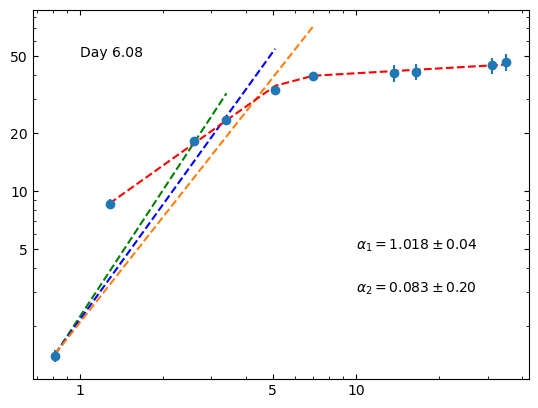

In [341]:
#plotting to check

fig,ax = plt.subplots()
mask = df2['Flux Density (mJy)'] > 3 * df2['Uncertainty (mJy)']  # apply detection threshold
mask2 = df2['Flux Density (mJy)'] < 3 * df2['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df2['Freq (GHz)'][mask], df2['Flux Density (mJy)'][mask], yerr=yerr2, fmt='o')
    ax.scatter(df2['Freq (GHz)'][mask2], (df2['Flux Density (mJy)'][mask2] + 3*df2['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 6.08', xy=(1, 50))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
 #   ax.plot(x3, fit_model_weights3(x3), 'r--')
    ax.plot(x4, fit_model_weights4(x4), 'g--')
    ax.plot(x5, fit_model_weights5(x5), 'b--')
    ax.plot(x6, fit_model_weights6(x6), '--')    
    ax.plot(x_new, fw_BPL2(x_new), 'r--')
    ax.annotate(r'$\alpha_1 = 1.018 \pm 0.04$', xy=(10, 5))
    ax.annotate(r'$\alpha_2 = 0.083 \pm 0.20$', xy=(10, 3))

plt.show();


# "Day 260-287" (df19_3)
# Named this day 273.5 (just took the average of these two days) 

In [284]:
x19_3 = df19_3['Freq (GHz)'].values.tolist()
y19_3 = df19_3['Flux Density (mJy)'].values.tolist()
yerr19 = df19_3['Uncertainty (mJy)'].values.tolist()


yerr19_3 = error(yerr19, x19_3, y19_3)

In [298]:
#split so that I am fitting the first two points and the last three 
xA = [0.44, 0.147]
xB = [1.36, 0.62, 0.44]

yA = [8.93, 26.8]
yB = [9.9, 10.14, 8.93]

erA = [0.943564120767635, 3.41250641025039]
erB = [0.4950000000000003, 0.518895943325827, 0.943564120767635]

In [299]:
PLA =  PowerLaw1D(amplitude = yA[0], x_0= xA[0], alpha= 1,
                     bounds={
        'amplitude': (0, None),  # Amplitude should be positive
        #'x_0': (x3[0], x3[0]),  # Frequency must stay within data
        'alpha': (-10, 10)  # Keep alpha within a realistic range
    },
                 fixed={'x_0': True}) 

fitA = fitting.LevMarLSQFitter(calc_uncertainties=True)

fit_modelA = fitA(PLA, xA, yA)
y_weightA = 1/ (np.power(erA,2))  

fit_model_weightsA = fitA(PLA, xA, yA, weights=y_weightA)

fit_model_weightsA

<PowerLaw1D(amplitude=8.93, x_0=0.44, alpha=1.00241107)>

In [300]:
alpha_er = two_points(yA,xA,erA)
print(alpha_er)

(-1.0024110653034926, 0.1509228705504639)


In [301]:
PLB =  PowerLaw1D(amplitude = yB[0], x_0= xB[0], alpha= -2.5) 
fitB = fitting.LevMarLSQFitter(calc_uncertainties=True)

fit_modelB = fitB(PLB, xB, yB)
y_weightB = 1/ (np.power(erB, 2))  

fit_model_weightsB = fitB(PLB, xB, yB, weights=y_weightB)


print(fit_model_weightsB)

Model: PowerLaw1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
       amplitude            x_0               alpha        
    ---------------- ----------------- --------------------
    9.90714184385861 2.003174921862132 0.007622999301837426


In [294]:
#fitB.fit_info

In [302]:
fvec = np.array([ 0.14868238, -0.53440828,  1.22684422])
var = np.var(fvec)

cov_x = np.array([[ 2.95387703e+31, -7.83260019e+32,  4.76833274e+14],
        [-7.83260019e+32,  2.07691874e+34, -1.26438723e+16],
        [ 4.76833274e+14, -1.26438723e+16,  9.56702577e-03]])


def stand(cov):
    diag = np.diagonal(cov)
    sd1 = np.sqrt(diag[0])
    sd2 = np.sqrt(diag[1])
    sd3 = np.sqrt(diag[2])
    return(sd1,sd2,sd3)

diag = stand(cov_x*var) 
print(diag)

(3940524239435980.0, 1.0448827272387469e+17, 0.07091633279562524)


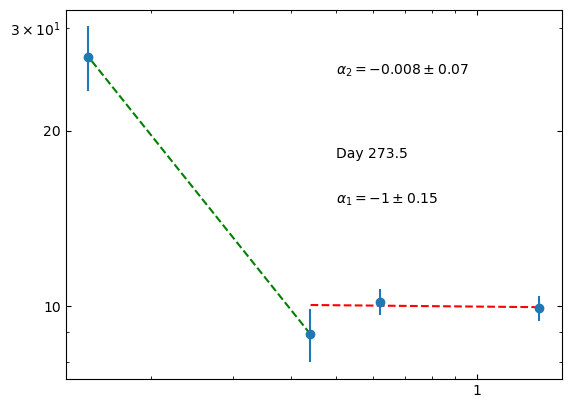

In [303]:
#plotting to check
fig,ax = plt.subplots()

x_freq = np.arange(0.15,2,0.5)
mask = df19_3['Flux Density (mJy)'] > 3 * df19_3['Uncertainty (mJy)']  # apply detection threshold
mask2 = df19_3['Flux Density (mJy)'] < 3 * df19_3['Uncertainty (mJy)']  # apply non-detection threshold
if mask.any():  # proceed only if at least one detection
    ax.errorbar(df19_3['Freq (GHz)'][mask], df19_3['Flux Density (mJy)'][mask], yerr=yerr19_3, fmt='o')
    ax.scatter(df19_3['Freq (GHz)'][mask2], (df19_3['Flux Density (mJy)'][mask2] + 3*df19_3['Uncertainty (mJy)'][mask2]), marker='v')
    ax.set_xscale('log')
    ax.set_xticks([1, 5, 10, 50], labels=['1', '5', '10', '50'])
    ax.set_yscale('log')
    ax.set_yticks([1, 5, 10, 20, 50], labels=['1', '5', '10', '20', '50'])
    ax.annotate('Day 273.5', xy=(0.5, 18))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
    ax.plot(xB, fit_model_weightsB(xB), 'r--')
    ax.plot(xA, fit_model_weightsA(xA), 'g--')
    ax.annotate(r'$\alpha_2 = -0.008 \pm 0.07$', xy=(0.5, 25))
    ax.annotate(r'$\alpha_1 = -1 \pm 0.15$', xy=(0.5, 15))

plt.show();